# The ATM implied volatility skew: Heston and the decomposition formula versus S&P 500 options
**TFG (BSc in Economics, Universitat Pompeu Fabra)** · Carles Aliern Fons · supervisor: Elisa Alòs

Every line of code has a comment that says what it does, why and where it comes from. The short library functions that are the core of this analysis (the market skew, the model skew and the power law) are **copied here with comments**, and it is checked that they give the same result as the library `heston_tfg.py`.

The data are read from the saved file `data\SPX_2026-10-08.csv` (options at the close of 7 October 2026, downloaded in the early hours of 8 October) and the interest rate from `..\Data\2026-10-07\market.csv`. **The notebook does not use the Internet**, so it always gives the same result.

**Research question.** Does the Heston model reproduce how the ATM skew of implied volatility changes with maturity in the S&P 500 options market? And does the decomposition formula (Alòs, 2012) approximate the Heston skew well?

**Motivation.** The ATM skew, ∂σ_imp/∂k at k = 0 (k = ln(K/F)), measures the asymmetry of the *smile*: the more negative it is, the more expensive the options that protect against falls are (leverage effect, ρ < 0).
- In Heston, as T → 0 the skew tends to a constant, ρν/(4σ₀) (σ₀ = √v0), and for long maturities it decreases approximately like 1/T.
- In the market, the skew grows like a **power law** T^(−α) as T becomes small, with α between roughly 0.3 and 0.5. This fact is the origin of fractional or "rough" volatility models: Alòs, León and Vives (2007); Gatheral, Jaisson and Rosenbaum (2018).
- The book chapter itself says that Heston has problems at short maturities (section 2.6.2, *Limitations*).

**Method.**
1. Data of one day: forward by put-call parity, out-of-the-money options and implied volatilities.
2. Market ATM skew at each maturity: local quadratic regression of implied volatility on k, near k = 0.
3. Calibration of Heston (Fourier prices).
4. Model ATM skew: exact (Fourier) and approximate (decomposition formula); check of the short-maturity limit ρν/(4σ₀).
5. Fit of the power law |skew| = c·T^(−α) to the market and to the model.
6. Conditional Monte Carlo (Milstein) as an independent check of the model prices.
7. Robustness checks: width of the band, step h of the derivative, ranges of maturities in the power law and bias of the market skew estimator.
8. Results and conclusions.

**Title of the thesis.** *The ATM Implied Volatility Skew under the Heston Model: Decomposition-Formula Approximations versus S&P 500 Options*

## 0. Setup

In [1]:
# --- Libraries ---
import os                                       # file paths (Windows and Linux)
import numpy as np                              # computation with vectors
import pandas as pd                             # tables
import matplotlib.pyplot as plt                 # plots
import heston_tfg as ht                         # our library (heston_tfg.py, in this folder)
from heston_experiment import heston_mc_conditional   # the book's conditional Monte Carlo (heston_experiment.py)

pd.set_option("display.width", 200)             # wide tables
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                     "legend.frameon": False, "lines.linewidth": 2, "figure.dpi": 110})   # plot style
C_MKT, C_FOU, C_DEC, C_INK = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"   # colours: market, Heston-Fourier, decomposition, text

# --- Risk-free rate: 13-week US Treasury bill (^IRX), of the same day as the options ---
market = pd.read_csv(os.path.join("..", "Data", "2026-10-07", "market.csv"))    # file of the daily download
R = float(market["IRX_13w_tbill_pct"].iloc[0]) / 100                           # it comes in %, we turn it into a decimal
print(f"Interest rate: r = {R:.4f}")

Interest rate: r = 0.0404


## 1. Data

Options on the S&P 500 index (`^SPX`, European) at the close of **7 October 2026**, downloaded from Yahoo Finance with the `yfinance` package. The 14 maturities closest to the horizons of 2, 4, 7, 10, 14, 21, 30, 45, 60, 90, 120, 180, 270 and 365 days were taken. The function `ht.build_clean_chain` (library `heston_tfg.py`) does the following:
1. price = midpoint between bid and ask;
2. forward F by put-call parity with the 3 strikes closest to the spot;
3. only out-of-the-money options (puts are turned into calls with the parity);
4. implied volatility by inverting the Black-76 formula (Brent's method);
5. quality filters (spread, small vega, points that jump).

In [2]:
raw = pd.read_csv(os.path.join("data", "SPX_2026-10-08.csv"))   # saved chain: one row per option (calls and puts)
SPOT = float(raw["spot"].iloc[0])                               # index price at the close
print(f"^SPX: spot {SPOT:.2f}, quotes of {raw['asof'].iloc[0]}, {len(raw)} options in the file")
chain = ht.build_clean_chain(raw, SPOT, r=R)                    # forward, out-of-the-money options, implied vols, filters
print("Cleaning (options removed at each step):", chain.attrs["cleaning"])
# Summary per maturity: days, forward, number of options and range of implied volatilities
chain.groupby("T").agg(days=("T", lambda t: round(t.iloc[0] * 365)), F=("F", "first"), n=("K", "size"),
                       iv_min=("iv", "min"), iv_max=("iv", "max")).round(4)

^SPX: spot 7801.77, quotes of 2026-10-07, 6515 options in the file


Cleaning (options removed at each step): {'options_before': 1945, 'last_price_quotes': 31, 'low_vega': 9, 'iv_outliers': 16, 'options_after': 1889}


,days,F,n,iv_min,iv_max
T,,,,,
0.005479,2,7802.1005,106,0.0964,0.2799
0.013699,5,7802.1512,95,0.0779,0.2695
0.019178,7,7803.5194,89,0.0912,0.2978
0.024658,9,7806.2963,53,0.0931,0.3490
0.038356,14,7808.8637,66,0.0951,0.3489
0.057534,21,7814.4938,46,0.1007,0.3572
0.082192,30,7823.7119,69,0.1077,0.2744
0.120548,44,7831.2302,112,0.1099,0.3355
0.147945,54,7837.8755,199,0.1085,0.3079


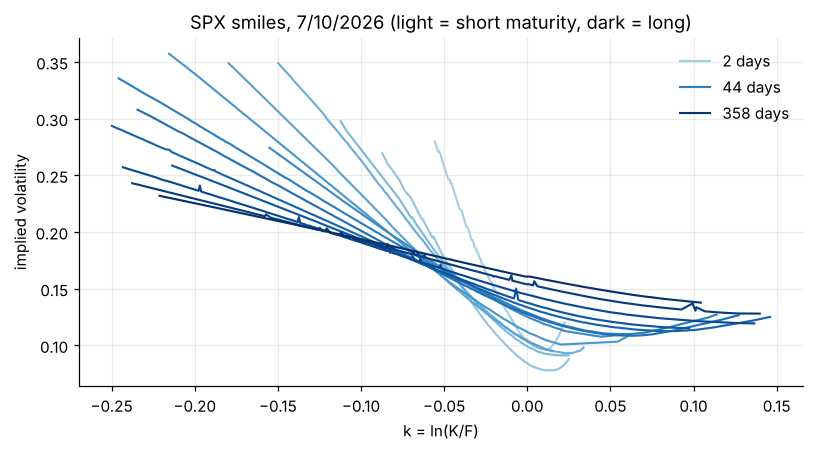

In [3]:
# Smiles of all maturities: implied volatility as a function of k = ln(K/F)
Ts = sorted(chain["T"].unique())                                # maturities, from shortest to longest
blues = plt.get_cmap("Blues")                                   # scale of blues: light = short, dark = long
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for i, T in enumerate(Ts):
    g = chain[chain["T"] == T]                                  # options of this maturity
    label = f"{round(T * 365)} days" if i in (0, len(Ts) // 2, len(Ts) - 1) else None   # legend only for 3
    ax.plot(np.log(g["K"] / g["F"]), g["iv"], "-", lw=1.4, color=blues(0.35 + 0.65 * i / (len(Ts) - 1)), label=label)
ax.set_xlabel("k = ln(K/F)"); ax.set_ylabel("implied volatility")
ax.set_title("SPX smiles, 7/10/2026 (light = short maturity, dark = long)"); ax.legend()
plt.tight_layout(); plt.savefig("fig_smiles.png", dpi=150); plt.show()

## 2. Market ATM skew at each maturity

For each maturity we fit by least squares (OLS) a parabola to the implied volatility near k = 0:

  σ_imp(k) ≈ a + b·k + c·k², only with the options that satisfy |k| ≤ max(0.01; 0.3·σ_ATM·√T).

- **a** is the ATM volatility (the value at k = 0).
- **b** is the **ATM skew** (the slope at k = 0), which is what we study.
- **2c** is the curvature.

**Why a parabola and not a straight line?** The *smile* is curved. If we fit a straight line, the curvature gets "mixed" with the slope and the skew comes out biased.

**Why a narrow band?** The further from k = 0, the more the higher-order terms that the parabola does not capture weigh. The width of the band depends on σ_ATM·√T, which is the standard deviation of ln(S_T/F): this way the band is "equally wide" for all maturities, measured in standard deviations. The band has a minimum of 0.01 because at very short maturities 0.3 standard deviations would leave too few strikes; up to 21 days it is this minimum that applies. In section 7 the estimator is checked by applying it to *smiles* generated by Heston, where the exact skew is known: from 14 days onwards it errs by less than 4%, but at maturities of 1–2 weeks it underestimates the skew (in absolute value) by between 13% and 27%. As a robustness check, we also compute it with a band of 0.5.

The **standard error** of b comes from the OLS covariance matrix, which `np.polyfit(..., cov=True)` computes.

In [4]:
def market_skew(chain, min_points=6, width=0.3):
    """Market ATM skew at each maturity (commented copy of ht.market_atm_skew)."""
    rows = []
    for T, g in chain.groupby("T"):                             # one maturity at a time
        g = g.sort_values("K")                                  # we sort by strike
        k = np.log(g["K"] / g["F"]).values                      # log-moneyness
        iv = g["iv"].values                                     # implied volatilities
        if len(k) < min_points or k.min() > 0 or k.max() < 0:   # we need enough points and k = 0 inside the data
            continue
        iv_atm = float(np.interp(0.0, k, iv))                   # approximate ATM volatility (linear interpolation at k = 0)
        band = max(0.01, width * iv_atm * np.sqrt(T))           # width of the band: 0.3 standard deviations (minimum 0.01)
        inside = np.abs(k) <= band                              # options inside the band
        if inside.sum() < min_points:                           # if there are few...
            inside = np.argsort(np.abs(k))[:min_points]         # ...we take the min_points closest to k = 0
        coef, cov = np.polyfit(k[inside], iv[inside], 2, cov=True)  # OLS of iv on (k², k, 1): coef = [c, b, a]
        rows.append(dict(T=T, days=round(T * 365), n=int(np.size(k[inside])),
                         atm_iv=coef[2],                        # a: ATM volatility
                         atm_skew=coef[1],                      # b: ATM skew
                         atm_skew_se=float(np.sqrt(cov[1, 1])), # standard error of b
                         curvature=2 * coef[0]))                # 2c: curvature
    return pd.DataFrame(rows)


mkt = market_skew(chain, width=0.3)                              # main band
mkt["atm_skew_band0.5"] = market_skew(chain, width=0.5)["atm_skew"].values   # robustness check
lib = ht.market_atm_skew(chain, width=0.3)                       # the library function
print("Maximum difference with the library:", float(np.max(np.abs(lib["atm_skew"].values - mkt["atm_skew"].values))))
mkt.round(4)

Maximum difference with the library: 0.0


,T,days,n,atm_iv,atm_skew,atm_skew_se,curvature,atm_skew_band0.5
0,0.0055,2,31,0.1038,-1.3953,0.0089,138.8582,-1.3953
1,0.0137,5,27,0.0841,-0.9146,0.0049,64.3636,-0.9146
2,0.0192,7,25,0.0992,-0.8256,0.0057,40.0300,-0.8256
3,0.0247,9,11,0.1035,-0.7935,0.0055,25.4773,-0.7935
4,0.0384,14,16,0.1043,-0.7835,0.0152,14.4503,-0.7831
5,0.0575,21,11,0.1119,-0.7163,0.0076,18.6100,-0.7219
6,0.0822,30,15,0.1253,-0.6742,0.0037,9.4171,-0.6686
7,0.1205,44,11,0.1288,-0.5866,0.0160,4.9736,-0.6006
8,0.1479,54,45,0.1275,-0.5715,0.0015,7.3090,-0.5651
9,0.2329,85,60,0.1336,-0.4965,0.0005,5.7251,-0.4908


## 3. Calibration of Heston (all maturities, Fourier prices)

`ht.calibrate` looks for the 5 parameters (κ, θ, ν, ρ, v0) that minimise Σ((model price − market price)/vega)², which is approximately the sum of squared errors in implied volatility. The model price is computed by Fourier (Little Heston Trap, Albrecher et al. 2007). It tries 3 starting points and keeps the best one. We use at most 40 options per maturity (`ht.thin_chain`). The notebook `calibration_by_maturity.ipynb` (folder `Calibration and Feller`) contains a version of the calibration commented line by line.

In [5]:
cal = ht.thin_chain(chain, max_per_T=40)                         # at most 40 options per maturity
params, fit, rmse, info = ht.calibrate(cal, R, pricer="fourier", return_info=True)   # global calibration
print("\nCalibrated parameters:", {k: round(v, 4) for k, v in params.items()})
print(f"RMSE error in implied volatility: {rmse * 100:.2f} points  |  {info['seconds']:.0f} s")
print(f"Feller: 2κθ − ν² = {ht.feller(params):.4f} ({'holds' if ht.feller(params) > 0 else 'does not hold'})")
fit["days"] = (fit["T"] * 365).round().astype(int)               # maturity in days
fit["abs_error"] = (fit["model_iv"] - fit["iv"]).abs() * 100     # absolute error in volatility points
fit.groupby("days")["abs_error"].mean().round(2).rename("mean error |model − market| (points)").to_frame().T

[fourier] start [ 2.     0.04   0.5   -0.7    0.078] -> cost 0.034309  params [ 1.09713e+01  3.72000e-02  1.86520e+00 -5.90500e-01  8.00000e-03]


[fourier] start [ 1.     0.06   0.3   -0.5    0.078] -> cost 0.034309  params [ 1.09706e+01  3.72000e-02  1.86510e+00 -5.90500e-01  8.00000e-03]


[fourier] start [ 5.     0.04   1.    -0.8    0.078] -> cost 0.034309  params [ 1.09705e+01  3.72000e-02  1.86510e+00 -5.90500e-01  8.00000e-03]



Calibrated parameters: {'kappa': 10.9713, 'theta': 0.0372, 'nu': 1.8652, 'rho': -0.5905, 'v0': 0.008}
RMSE error in implied volatility: 1.56 points  |  126 s
Feller: 2κθ − ν² = -2.6619 (does not hold)


days,2,5,7,9,14,21,30,44,54,85,114,175,266,358
mean error |model − market| (points),2.98,1.42,1.03,1.93,0.9,0.79,0.91,0.88,0.46,0.38,0.47,0.59,0.58,0.56


## 4. Model ATM skew: Fourier, decomposition formula and market

**Model skew by central differences.** If we have a pricing formula, we can compute the implied volatility at k = −h and at k = +h and approximate the derivative by:

  skew ≈ (σ_imp(+h) − σ_imp(−h)) / (2h), with h = 0.002.

It is the definition of the derivative with a small h. The error of this approximation is proportional to h². With h = 0.002 it is negligible from one month onwards, but at maturities of a few days, where the *smile* is very curved, it underestimates the skew by up to 2.6% (section 7). If h is too small, on the other hand, the rounding errors of the price are divided by a very small number. We do it with the Fourier price (exact) and with the decomposition formula (approximate). Since the skew is measured in terms of k = ln(K/F), we can set F = 1 and r = 0 without loss of generality.

**Short-maturity limit.** In Heston, as T → 0, the skew tends to ρν/(4σ₀) with σ₀ = √v0. We check it.

**Calibration with maturities of one month or more only.** If Heston fails at short maturities, perhaps it is because these maturities "pull" the parameters. We also calibrate with T ≥ 30 days only and look at what the model predicts for the short maturities.

**Power law.** If |skew| = c·T^(−α), taking logarithms gives ln|skew| = ln c − α·ln T, which is a straight line. We estimate it by OLS of ln|skew| on ln T: the slope is −α. We do it with all market maturities, with those of 60 days or less only, and with the Heston skew at the same maturities.

In [6]:
def skew_model(p, Ts, pricer="fourier", h=0.002):
    """ATM volatility and ATM skew of a model by central differences (commented copy of ht.model_atm_skew)."""
    price = ht.PRICERS[pricer]                                  # ht.heston_call_fwd (Fourier) or ht.decomp_call_fwd (decomposition)
    rows = []
    for T in np.atleast_1d(Ts):
        K = np.exp(np.array([-h, 0.0, h]))                      # strikes with k = −h, 0, +h (with F = 1)
        c = price(1.0, K, T, 0.0, p["kappa"], p["theta"], p["nu"], p["rho"], p["v0"])  # call prices (F = 1, r = 0)
        iv = [ht.implied_vol_fwd(x, 1.0, k, T, 0.0) for x, k in zip(c, K)]           # implied volatilities
        rows.append(dict(T=float(T), atm_iv=iv[1], atm_skew=(iv[2] - iv[0]) / (2 * h)))  # central difference
    return pd.DataFrame(rows)


def power_law(T, skew):
    """Fit |skew| = c·T^(−α) by OLS of ln|skew| on ln T (commented copy of ht.fit_power_law)."""
    T, skew = np.asarray(T, float), np.asarray(skew, float)
    neg = skew < 0                                              # only negative skews (the logarithm needs |skew| > 0)
    x, y = np.log(T[neg]), np.log(-skew[neg])                   # ln T and ln|skew|
    slope, constant = np.polyfit(x, y, 1)                       # straight line by OLS: y = constant + slope·x
    residuals = y - (constant + slope * x)
    r2 = 1 - residuals.var() / y.var()                          # R² of the regression
    return dict(alpha=-slope, c=np.exp(constant), r2=r2, n=int(neg.sum()))   # α = −slope, c = e^constant


T_grid = np.geomspace(1 / 365, 1.0, 40)                          # 40 maturities from 1 day to 1 year, spread on a log scale
sk_fou = skew_model(params, T_grid, pricer="fourier")            # exact Heston skew
sk_dec = skew_model(params, T_grid, pricer="decomposition")      # skew with the decomposition formula
limit = params["rho"] * params["nu"] / (4 * np.sqrt(params["v0"]))   # short-maturity limit ρν/(4σ₀)
print(f"Heston limit ρν/(4σ₀) = {limit:.4f};  Fourier skew at 1 day = {sk_fou['atm_skew'].iloc[0]:.4f}")
print("Maximum difference with ht.model_atm_skew:",
      float(np.max(np.abs(ht.model_atm_skew(params, T_grid)["atm_skew"].values - sk_fou["atm_skew"].values))))

# Heston calibrated only with maturities of 30 days or more: what does it predict for short maturities?
long_mats = cal[(cal["T"] * 365).round() >= 30].reset_index(drop=True)   # rounded days (avoids problems with decimals)
params_long, _, rmse_long = ht.calibrate(long_mats, R, pricer="fourier", verbose=False)
sk_long = skew_model(params_long, T_grid, pricer="fourier")
print("Parameters calibrated with T ≥ 30 days:", {k: round(v, 4) for k, v in params_long.items()})

# Power laws
pl_mkt = power_law(mkt["T"], mkt["atm_skew"])                    # market, all maturities
short = (mkt["T"] * 365).round() <= 60                           # maturities of 60 days or less
pl_mkt_short = power_law(mkt.loc[short, "T"], mkt.loc[short, "atm_skew"])
sk_hes = skew_model(params, mkt["T"].values, pricer="fourier")   # Heston at the same maturities as the market
pl_hes = power_law(sk_hes["T"], sk_hes["atm_skew"])
pd.DataFrame({"market (all maturities)": pl_mkt, "market (≤ 60 days)": pl_mkt_short,
              "Heston (same maturities)": pl_hes}).T.round(3)

Heston limit ρν/(4σ₀) = -3.0864;  Fourier skew at 1 day = -3.1017


Maximum difference with ht.model_atm_skew: 0.0


Parameters calibrated with T ≥ 30 days: {'kappa': 5.1166, 'theta': 0.0426, 'nu': 1.4197, 'rho': -0.6223, 'v0': 0.0158}


,alpha,c,r2,n
market (all maturities),0.266,0.321,0.972,14.0
market (≤ 60 days),0.238,0.354,0.928,9.0
Heston (same maturities),0.535,0.251,0.976,14.0


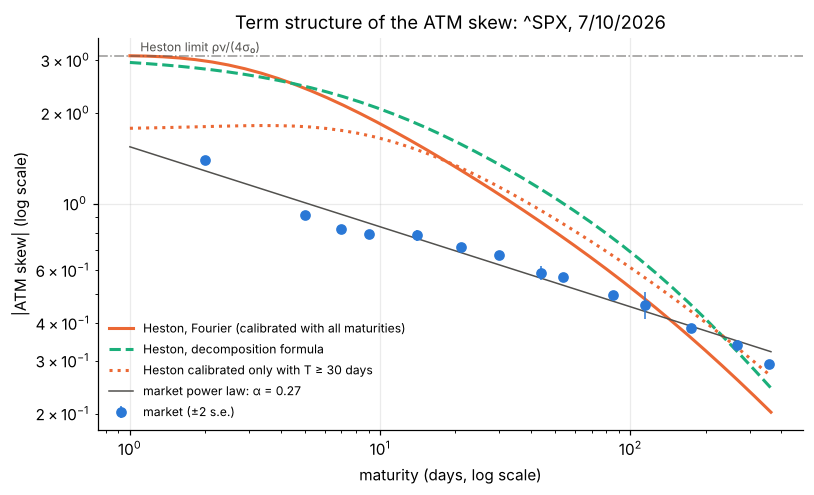

In [7]:
# The main plot: |skew| as a function of maturity, on a log-log scale (a power law shows up as a straight line)
fig, ax = plt.subplots(figsize=(7.5, 4.6))
d = 365                                                          # to go from years to days
ax.errorbar(mkt["T"] * d, -mkt["atm_skew"], yerr=2 * mkt["atm_skew_se"], fmt="o", ms=6, color=C_MKT,
            ecolor=C_MKT, elinewidth=1, capsize=0, label="market (±2 s.e.)", zorder=3)
ax.plot(T_grid * d, -sk_fou["atm_skew"], color=C_FOU, label="Heston, Fourier (calibrated with all maturities)")
ax.plot(T_grid * d, -sk_dec["atm_skew"], "--", color=C_DEC, label="Heston, decomposition formula")
ax.plot(T_grid * d, -sk_long["atm_skew"], ":", color=C_FOU, label="Heston calibrated only with T ≥ 30 days")
ax.plot(T_grid * d, pl_mkt["c"] * T_grid ** (-pl_mkt["alpha"]), "-", lw=1, color=C_INK,
        label=f"market power law: α = {pl_mkt['alpha']:.2f}")
ax.axhline(-limit, lw=1, ls="-.", color=C_INK, alpha=0.6)        # Heston short-maturity limit
ax.text(T_grid[0] * d * 1.1, -limit * 1.04, "Heston limit ρν/(4σ₀)", color=C_INK, fontsize=8)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("maturity (days, log scale)"); ax.set_ylabel("|ATM skew| (log scale)")
ax.set_title("Term structure of the ATM skew: ^SPX, 7/10/2026")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig("fig_skew_term_structure.png", dpi=150); plt.show()

## 5. Accuracy of the decomposition formula for the skew (calibrated parameters)

Relative error = decomposition skew / Fourier skew − 1, in %. The formula is an approximation in powers of ν, the volatility of volatility, and here ν ≈ 1.9 is very large.

In [8]:
comp = pd.DataFrame({"days": (T_grid * 365).round(1), "Fourier": sk_fou["atm_skew"], "decomposition": sk_dec["atm_skew"]})
comp["relative error %"] = (comp["decomposition"] / comp["Fourier"] - 1) * 100   # error of the formula with respect to the exact one
comp.iloc[::5].round(4)                                          # one row out of five

,days,Fourier,decomposition,relative error %
0,1.0,-3.1017,-2.9462,-5.0153
5,2.1,-2.9568,-2.7847,-5.8197
10,4.5,-2.4938,-2.5020,0.3291
15,9.7,-1.8692,-2.0842,11.4989
20,20.6,-1.3036,-1.5891,21.9036
25,43.9,-0.8675,-1.1167,28.7186
30,93.5,-0.5492,-0.7218,31.4113
35,199.3,-0.3248,-0.4140,27.4712


## 6. Independent check: conditional Monte Carlo (Milstein + reflection) with the calibrated parameters

Price of an ATM call: exact (Fourier) against the book's conditional Monte Carlo with m = 100, 400 and 1,600 steps (100,000 paths). **z** = (Monte Carlo − exact) / standard error: if |z| > 2, the Monte Carlo is biased. Since the Feller condition does not hold, the reflection that avoids negative variances creates a bias that decreases very slowly with m. In `feller_monte_carlo.ipynb` (folder `Calibration and Feller`) this is studied in depth and compared with other methods.

In [9]:
p = params                                                       # calibrated parameters
rows = []
for days in (7, 30, 180):                                        # three maturities
    T = days / 365
    exact = ht.heston_call_fwd(1.0, [1.0], T, 0.0, p["kappa"], p["theta"], p["nu"], p["rho"], p["v0"])[0]   # Fourier, F = K = 1
    for m in (100, 400, 1600):                                   # number of Monte Carlo steps
        mc, se = heston_mc_conditional(1.0, 1.0, p["v0"], 0.0, T, p["kappa"], p["theta"], p["nu"], p["rho"],
                                       m=m, n=100_000, seed=1)   # price and standard error
        rows.append(dict(days=days, steps=m, exact=exact, mc=mc, std_error=se, z=(mc - exact) / se))
print(f"Feller: 2κθ − ν² = {ht.feller(p):.3f}")
pd.DataFrame(rows).round(5)

Feller: 2κθ − ν² = -2.662


,days,steps,exact,mc,std_error,z
0,7,100,0.00484,0.00501,0.00001,31.14049
1,7,400,0.00484,0.00495,0.00001,21.86834
2,7,1600,0.00484,0.00492,0.00001,15.58172
3,30,100,0.01237,0.01383,0.00001,98.80619
4,30,400,0.01237,0.01336,0.00001,76.41810
5,30,1600,0.01237,0.01307,0.00001,57.07399
6,180,100,0.04301,0.05177,0.00007,122.75059
7,180,400,0.04301,0.04869,0.00006,95.93737
8,180,1600,0.04301,0.04691,0.00005,73.80257


## 7. Robustness: the band, the step h, the ranges of maturities and the skew estimator

Four method decisions could change the results. We check them one by one:

- **(a) The width of the band** of the quadratic regression of the market skew (0.3 standard deviations; we compare it with 0.5).
- **(b) The step h** of the central differences of the model skew. If h is large, the central difference also picks up the higher-order terms of the *smile* (error proportional to h²). If h is very small, the difference between the two implied volatilities is smaller than the rounding errors of the Fourier price and of the implied volatility computation, and these errors are divided by 2h.
- **(c) Which maturities enter the power law:** all of them, only those of one month or less, only those of two months or less, or only those of more than two months. If the market followed a power law exactly, α should come out the same in all ranges. We also do it with the Heston skew at the same maturities.
- **(d) The bias of the market skew estimator.** We use Heston as a "laboratory": we replace the market implied volatilities with those of Heston (calibrated parameters) **at the same strikes** and apply `market_skew` to them. Since the exact Heston skew is known (central differences with a very small h), the difference is the bias of the estimator. Moreover, this way we can compare market and model **with the same estimator**.

In [10]:
# (a) Width of the band: 0.3 against 0.5 standard deviations
band_diff = (mkt["atm_skew_band0.5"] / mkt["atm_skew"] - 1) * 100       # relative difference of the skew, in %
pl_05 = power_law(mkt["T"], mkt["atm_skew_band0.5"])                     # power law with the 0.5 band
print(f"(a) Band 0.5 against 0.3: the skew changes between {band_diff.min():.1f}% and {band_diff.max():.1f}%;"
      f"  α = {pl_05['alpha']:.3f} with the 0.5 band and {pl_mkt['alpha']:.3f} with the 0.3 one")
print("    Maturities where both bands stay at the minimum of 0.01 (and therefore give the same skew):",
      list(mkt.loc[band_diff == 0, "days"]))

# (b) The step h: Heston skew (calibrated parameters, Fourier) at 2, 7, 30 and 180 days with six values of h
test_days = [2, 7, 30, 180]
table_h = pd.DataFrame({"days": test_days})
for h in [0.2, 0.02, 0.002, 1e-4, 1e-5, 1e-8]:                           # from very large to very small
    table_h[f"h = {h:g}"] = skew_model(params, np.array(test_days) / 365, h=h)["atm_skew"].values
print("\n(b) Heston ATM skew depending on the step h of the central differences:")
display(table_h.round(4))
sk_short = skew_model(params, np.array([0.1, 1]) / 365, h=1e-5)["atm_skew"].values   # exact derivative, very short maturities
print(f"    With h = 1e-5: skew at 0.1 days = {sk_short[0]:.4f}, at 1 day = {sk_short[1]:.4f};  limit ρν/(4σ₀) = {limit:.4f}")

# (c) Power law with different ranges of maturities, in the market and in Heston (the same maturities)
mkt_days = (mkt["T"] * 365).round()                                      # market maturities in days
ranges = {"all": mkt_days > 0, "≤ 30 days": mkt_days <= 30, "≤ 60 days": mkt_days <= 60, "> 60 days": mkt_days > 60}
rows = []
for name, f in ranges.items():
    m_ = power_law(mkt.loc[f, "T"], mkt.loc[f, "atm_skew"])              # market
    h_ = power_law(sk_hes.loc[f.values, "T"], sk_hes.loc[f.values, "atm_skew"])   # calibrated Heston
    rows.append(dict(range=name, n=m_["n"], alpha_market=m_["alpha"], r2_market=m_["r2"],
                     alpha_heston=h_["alpha"], r2_heston=h_["r2"]))
print("\n(c) Exponent α of the power law depending on the maturities included:")
display(pd.DataFrame(rows).round(3))

(a) Band 0.5 against 0.3: the skew changes between -2.7% and 2.4%;  α = 0.269 with the 0.5 band and 0.266 with the 0.3 one
    Maturities where both bands stay at the minimum of 0.01 (and therefore give the same skew): [2, 5, 7, 9]

(b) Heston ATM skew depending on the step h of the central differences:


,days,h = 0.2,h = 0.02,h = 0.002,h = 0.0001,h = 1e-05,h = 1e-08
0,2,0.0108,-1.2740,-2.9808,-3.0605,-3.0607,-3.0607
1,7,NaN,-1.1697,-2.1386,-2.1622,-2.1622,-2.1622
2,30,-0.2651,-0.9116,-1.0708,-1.0727,-1.0727,-1.0727
3,180,-0.2258,-0.3479,-0.3501,-0.3502,-0.3502,-0.3502


    With h = 1e-5: skew at 0.1 days = -3.1027, at 1 day = -3.1874;  limit ρν/(4σ₀) = -3.0864

(c) Exponent α of the power law depending on the maturities included:


,range,n,alpha_market,r2_market,alpha_heston,r2_heston
0,all,14,0.266,0.972,0.535,0.976
1,≤ 30 days,7,0.247,0.884,0.386,0.970
2,≤ 60 days,9,0.238,0.928,0.429,0.975
3,> 60 days,5,0.368,0.994,0.727,0.999


In [11]:
# (d) The market skew estimator, applied to Heston smiles (where the exact skew is known)
rows = []
for T, g in chain.groupby("T"):                                          # same maturities and strikes as the market
    g = g.copy()
    F, K = g["F"].iloc[0], g["K"].values
    prices = ht.heston_call_fwd(F, K, T, R, params["kappa"], params["theta"], params["nu"], params["rho"], params["v0"])
    g["iv"] = [ht.implied_vol_fwd(c, F, k, T, R) for c, k in zip(prices, K)]  # Heston smile instead of the market one
    g = g[np.isfinite(g["iv"])]                                          # (in case some volatility does not exist)
    estimated = market_skew(g)["atm_skew"].iloc[0]                       # the SAME estimator that we use for the market
    exact = skew_model(params, [T], h=1e-5)["atm_skew"].iloc[0]          # exact Heston skew (very small h)
    mkt_row = mkt[mkt["T"] == T].iloc[0]                                 # the market at this maturity
    band = max(0.01, 0.3 * mkt_row["atm_iv"] * np.sqrt(T))               # width of the band (as in market_skew)
    rows.append(dict(days=round(T * 365), band_in_sd=band / (mkt_row["atm_iv"] * np.sqrt(T)),
                     market=mkt_row["atm_skew"], heston_same_estimator=estimated, heston_exact=exact,
                     estimator_bias_pct=(estimated / exact - 1) * 100))
lab = pd.DataFrame(rows)
print("(d) ATM skew: market, Heston with the same estimator as the market and exact Heston")
display(lab.round(3))
pl_lab = {"market": power_law(lab["days"] / 365, lab["market"]),
          "Heston, same estimator": power_law(lab["days"] / 365, lab["heston_same_estimator"]),
          "Heston, exact": power_law(lab["days"] / 365, lab["heston_exact"])}
pd.DataFrame(pl_lab).T.round(3)

(d) ATM skew: market, Heston with the same estimator as the market and exact Heston


,days,band_in_sd,market,heston_same_estimator,heston_exact,estimator_bias_pct
0,2,1.302,-1.395,-2.233,-3.061,-27.059
1,5,1.015,-0.915,-1.988,-2.454,-19.004
2,7,0.728,-0.826,-1.823,-2.162,-15.675
3,9,0.615,-0.794,-1.700,-1.945,-12.592
4,14,0.490,-0.784,-1.541,-1.586,-2.815
5,21,0.373,-0.716,-1.246,-1.295,-3.785
6,30,0.300,-0.674,-1.042,-1.073,-2.823
7,44,0.300,-0.587,-0.870,-0.867,0.266
8,54,0.300,-0.571,-0.756,-0.770,-1.866
9,85,0.300,-0.497,-0.575,-0.584,-1.562


,alpha,c,r2,n
market,0.266,0.321,0.972,14.0
"Heston, same estimator",0.486,0.264,0.950,14.0
"Heston, exact",0.539,0.249,0.978,14.0


## 8. Results and conclusions

Data: options on the S&P 500 index (^SPX) at the close of 7 October 2026, 1,889 out-of-the-money options after cleaning, 14 maturities from 2 to 358 days.

### 8.1 The market: the ATM skew approximately follows a power law

The market ATM skew goes from −1.40 at 2 days to −0.29 at one year, and the log-log fit gives **|skew| ≈ 0.32·T^(−0.27)**, with R² = 0.97. By ranges of maturities, α is 0.25 (≤ 30 days), 0.24 (≤ 60 days) and 0.37 (> 60 days): it is not an exact power law, but the exponent changes little from one range to another. A power law means that the skew is multiplied by the same factor every time the maturity is divided by the same factor: with α = 0.27, if the maturity is divided by 10, the skew is multiplied by 10^0.27 ≈ 1.9.

### 8.2 Heston does not reproduce the shape of the term structure of the skew

Calibrated with all maturities (κ = 10.97, θ = 0.0372, ν = 1.87, ρ = −0.59, v0 = 0.0080; RMSE error of 1.56 volatility points, about 3 points at 2 days and less than 1 point from two weeks onwards):

- **At short maturities, the Heston skew is too steep.** It tends to the constant ρν/(4σ₀) = −3.09 (section 7 confirms it: with the exact derivative, the skew is −3.10 at 0.1 days). At 2 days it is −3.06, 2.2 times that of the market; at 7 days, 2.6 times; at 30 days, 1.6 times (exact derivative, column `heston_exact` of table (d) in section 7).
- **At long maturities, it is too small:** at one year, −0.21 against −0.29 for the market. The two curves cross between 4 and 6 months.
- **The exponent is not the same.** α is 0.54 for Heston and 0.27 for the market. By ranges, for Heston it goes from 0.39 (≤ 30 days) to 0.73 (> 60 days): the Heston skew is almost constant at very short maturities and falls almost like 1/T at long ones, while that of the market falls at a similar rate at all maturities.
- **Calibrated only with T ≥ 30 days** (κ = 5.12, θ = 0.0426, ν = 1.42, ρ = −0.62, v0 = 0.0158), Heston gets closer to the market at one year (−0.27), but its skew stays flat between 1 and 7 days (≈ −1.8, its limit ρν/(4σ₀) = −1.76) and does not grow like that of the market as maturity shrinks.

Conclusion: with constant parameters, Heston can fit the short maturities or the long ones more or less well, but it cannot generate a skew that grows like T^(−0.27) at all maturities at the same time. This is consistent with `calibration_by_maturity.ipynb`: if Heston is calibrated maturity by maturity, ν has to grow as maturity shrinks. Fractional or "rough" volatility models (Alòs, León and Vives, 2007; Gatheral, Jaisson and Rosenbaum, 2018) generate this behaviour naturally.

### 8.3 The decomposition formula, with these parameters, has large errors in the skew

Relative error of the skew of the decomposition formula with respect to that of Fourier: −5% at 1–2 days (−8 or −9% if the derivative is computed with a small h, section 7), practically 0 at 4–5 days, +11% at 10 days, +22% at 3 weeks, between +29% and +31% between a month and a half and three months, and +27% at six and a half months. The formula is an approximation obtained by expanding in the volatility of volatility, and here ν ≈ 1.9 is very large. `feller_monte_carlo.ipynb` (experiment 4) shows that the error comes from the large ν and not from the Feller condition: with ν = 0.3 the formula misses the ATM price by less than 0.12 volatility points even with a Feller ratio of 0.1.

### 8.4 The book's conditional Monte Carlo is not useful as a check with these parameters

Against the exact Fourier price, it has z between 16 and 123: it is a bias, not noise, and it decreases very slowly as the number of steps increases (at 30 days, z = 99, 76 and 57 with 100, 400 and 1,600 steps). The Feller ratio of the calibrated parameters is φ = 2κθ/ν² = 0.23. `feller_monte_carlo.ipynb` explains why: the book's Monte Carlo simulates the variance with Milstein and reflection, which is biased when φ < 1/2. To check prices with Monte Carlo, Andersen's (2008) QE scheme or the exact simulation of the variance must be used.

### 8.5 Robustness (section 7)

- **Band of 0.5 instead of 0.3:** the market skew changes between −2.7% and +2.4%, and α goes from 0.266 to 0.269. But at maturities of 2 to 9 days both bands stay at the minimum of 0.01 and give exactly the same result, so this test says nothing about the shortest maturities.
- **Bias of the skew estimator (d):** applied to Heston *smiles*, the estimator errs by less than 4% from 14 days onwards, but underestimates the skew (in absolute value) by 27% at 2 days, 19% at 5, 16% at 7 and 13% at 9. The reason is the minimum of 0.01: at 2 days, ±0.01 is 1.3 standard deviations (not 0.3), and that far from k = 0 the parabola no longer describes the *smile* well. Therefore, the market skew of less than two weeks is probably also underestimated in absolute value, and the fair comparison is to apply the same estimator to the market and to the model. Doing so, conclusion 8.2 does not change: Heston gives −2.23 at 2 days and −1.82 at 7 days, against −1.40 and −0.83 for the market, and α = 0.49 against 0.27.
- **Step h:** with h = 0.002, the Heston skew is underestimated by 2.6% at 2 days, 1.1% at 7 days and less than 0.2% from 30 days onwards. With h between 10⁻⁸ and 10⁻⁴ the results coincide up to the fourth decimal (rounding errors only appear below 10⁻¹⁰). With h = 0.2 the result makes no sense at short maturities (it even comes out as NaN or with the wrong sign). No conclusion changes: the Heston α goes from 0.535 to 0.539.
- **Ranges of maturities:** market α between 0.24 and 0.37 depending on the range; Heston α between 0.39 and 0.73. As said in 8.2, the difference between ranges is much larger for Heston than for the market.

### 8.6 Limitations

- A single day of data (7 October 2026). The term structure of the skew can change with the level of the market and with volatility.
- The calibration minimises price errors divided by the vega, which gives little weight to the wings of the short maturities (`calibration_by_maturity.ipynb` calibrates maturity by maturity with the exact error in implied volatility).
- At maturities of less than two weeks, the market skew depends on the estimator (8.5).
- The decomposition formula has been evaluated with a single set of parameters, with a very large ν.

### References

- Albrecher, H., Mayer, P., Schoutens, W. and Tistaert, J. (2007). The little Heston trap. *Wilmott Magazine*, January, 83–92.
- Alòs, E. (2012). A decomposition formula for option prices in the Heston model and applications to option pricing approximation. *Finance and Stochastics*, 16(3), 403–422.
- Alòs, E., León, J. A. and Vives, J. (2007). On the short-time behavior of the implied volatility for jump-diffusion models with stochastic volatility. *Finance and Stochastics*, 11(4), 571–589.
- Alòs, E. and Merino, R. *Introduction to Financial Derivatives with Python*. CRC Press.
- Andersen, L. (2008). Simple and efficient simulation of the Heston stochastic volatility model. *Journal of Computational Finance*, 11(3), 1–42.
- Gatheral, J., Jaisson, T. and Rosenbaum, M. (2018). Volatility is rough. *Quantitative Finance*, 18(6), 933–949.
- Heston, S. L. (1993). A closed-form solution for options with stochastic volatility with applications to bond and currency options. *Review of Financial Studies*, 6(2), 327–343.